<center> <p style="text-align:center;font-family:arial"> <b>Universidade Federal de Alagoas</b></p>


<p style="text-align:center;font-family:arial"> <b>Instituto de Computação - PPGI - IC</b></p>


<p style="text-align:center;font-family:arial"> <b>Processamento de Linguagem Natural</b></p></center>


<p style="font-family:arial">Professor: Thales Vieira</p>

<p style="font-family:arial">Aluno: Edvonaldo Horácio dos Santos ( matrícula 2022104210)</p>

<center><p style="text-align:center;font-family:arial"> <b>3ª Lista de Exercícios</>

In [ ]:
# Import libs
import os
import re
import nltk
import random
import string
import spacy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.tokenize import RegexpTokenizer
from google.colab import drive

# Pré-processamento

In [ ]:
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = '/content/drive/MyDrive/dataset_pln_2022.2/corpus_bcc.csv'

In [ ]:
df_corpus = pd.read_csv(path, sep=';')
print("Shape dataframe: ", df_corpus.shape)
df_corpus.describe()

Shape dataframe:  (2225, 4)


,Unnamed: 0,id
count,2225.000000,2225.000000
mean,225.321798,226.321798
std,134.218688,134.218688
min,0.000000,1.000000
25%,111.000000,112.000000
50%,222.000000,223.000000
75%,333.000000,334.000000
max,510.000000,511.000000


In [ ]:
df_corpus.head()

,Unnamed: 0,id,content,label
0,0,1,Ad sales boost Time Warner profit\n\nQuarterly...,business
1,1,2,Dollar gains on Greenspan speech\n\nThe dollar...,business
2,2,3,Yukos unit buyer faces loan claim\n\nThe owner...,business
3,3,4,High fuel prices hit BA's profits\n\nBritish A...,business
4,4,5,Pernod takeover talk lifts Domecq\n\nShares in...,business


In [ ]:
# Removendo todas as palavras que contem números
df_corpus['content'] = df_corpus['content'].replace(to_replace=r'\w*\d\w*', value='', regex=True)
#print(df_corpus)

In [ ]:
# Transformando todas as palavras em minúsculas
for idx_txt in range(df_corpus['content'].shape[0]):
  df_corpus['content'][idx_txt] = df_corpus['content'][idx_txt].lower()

<ipython-input-7-1765ecc0b32f>:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_corpus['content'][idx_txt] = df_corpus['content'][idx_txt].lower()


In [ ]:
# Removendo pontuação
def remove_punctuation(txt):
  return re.sub('[%s]' % re.escape(string.punctuation), ' ', txt)

df_corpus['content'] = df_corpus['content'].apply(remove_punctuation)

In [ ]:
# Tokenizando
from nltk.tokenize import sent_tokenize, word_tokenize 
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

In [ ]:
df_corpus.columns

Index(['Unnamed: 0', 'id', 'content', 'label'], dtype='object')

In [ ]:
data = []
for text in range(df_corpus['content'].shape[0]):
  data_aux = []
  for i in sent_tokenize(df_corpus['content'][text]): 
      temp = [] 

      # tokenize sentença para palavra 
      for j in word_tokenize(remove_punctuation(i)): ## Retirando a pontuação
          
          temp.append(j.lower()) 

      data_aux.append(temp) 
  data.append((text, data_aux)) 

In [ ]:
print(len(data))
data[0][1][0][0]

2225


'ad'

# Questão 1

## (a) Modelo word2vec para os textos

In [ ]:
import gensim 
from gensim.test.utils import common_texts
from gensim.models import Word2Vec

model = Word2Vec(sentences=common_texts, size=100, window=5, min_count=1, workers=4)

common_texts

[['human', 'interface', 'computer'],
 ['survey', 'user', 'computer', 'system', 'response', 'time'],
 ['eps', 'user', 'interface', 'system'],
 ['system', 'human', 'system', 'eps'],
 ['user', 'response', 'time'],
 ['trees'],
 ['graph', 'trees'],
 ['graph', 'minors', 'trees'],
 ['graph', 'minors', 'survey']]

In [ ]:
import gensim.downloader as api
word_vectors50 = api.load("glove-wiki-gigaword-50")
#word_vectors100 = api.load("glove-wiki-gigaword-100")
#word_vectors200 = api.load("glove-wiki-gigaword-200")

#models = [(word_vectors50, 'Com 50'), (word_vectors100, 'Com 100'), (word_vectors200, 'Com 200')]
models = [(word_vectors50, 'Com 50')]

[==================================================] 100.0% 66.0/66.0MB downloaded


## (b) 5 palavras de consulta que não estão em nenhum dos textos. Para cada palavra, encontrar 3 do corpus mais parecidas

In [ ]:
words_to_compare = ['walmart', 'pineapple', 'platypus', 'wolframalpha', 'javascript']
for model in models:
  print('***************** Resultados ' + model[1] + ' *****************')
  for word in words_to_compare:
    result = []
    for docum in range(0, len(data)): ##Por documento
      for vects in range(0, len(data[docum][1])): ## Vetor de vetores de palavras
        for arr in range(0, len(data[docum][1][vects])): ## Vetor de palavra
          try:
            word_acc = data[docum][1][vects][arr] ## palavra
            similarity = model[0].similarity(word, word_acc)
            result.append((data[docum][1][vects][arr], docum, similarity))
          except Exception as e:
            pass
          finally:
            pass
    result.sort(key=lambda tup: tup[2], reverse=True)
    print('Para a palavra ' + word)
    print("1° {palavra} | texto: {text} | similaridade de {sim:.2f}".format(palavra = result[0][0], text = result[0][1], sim = result[0][2]) )
    id = 1
    while(result[0][0] == result[id][0]):
      id +=1
    print("2° {palavra} | texto: {text} | similaridade de {sim:.2f}".format(palavra = result[id][0], text = result[id][1], sim = result[id][2]) )
    id2 = id + 1
    while(result[id2][0] == result[id][0]):
      id2 +=1
    print("3° {palavra} | texto: {text} | similaridade de {sim:.2f}".format(palavra = result[id2][0], text = result[id2][1], sim = result[id2][2]) )
    print("----------------------------------------------------------------")

***************** Resultados Com 50 *****************
Para a palavra walmart
1° costco | texto: 405 | similaridade de 0.79
2° mart | texto: 69 | similaridade de 0.76
3° wal | texto: 69 | similaridade de 0.76
----------------------------------------------------------------
Para a palavra pineapple
1° juice | texto: 624 | similaridade de 0.81
2° plum | texto: 1492 | similaridade de 0.78
3° banana | texto: 862 | similaridade de 0.76
----------------------------------------------------------------
Para a palavra platypus
1° hamster | texto: 2198 | similaridade de 0.62
2° feline | texto: 2089 | similaridade de 0.57
3° hobbit | texto: 894 | similaridade de 0.57
----------------------------------------------------------------
Para a palavra wolframalpha
1° offputting | texto: 815 | similaridade de 0.73
2° nienhuis | texto: 2185 | similaridade de 0.69
3° vindictively | texto: 1007 | similaridade de 0.67
----------------------------------------------------------------
Para a palavra javascript


## (c) Algoritmo

### 1. Encontrar d10(w): 10 palavras mais parecidas com w em um documento d

### 2. Para cada d, calcular a distância média DM10(w) entre w e cada d10(w)

In [ ]:
word_search = ['walmart'] # Colocando a palavra que desejar ser buscada em algum documento

for model in models:
  #print('***************** Resultados ' + model[1] + ' *****************')
  for word in word_search:
    result_ws = []
    for docum in range(0, len(data)): ## Por documento
      for vects in range(0, len(data[docum][1])): ## Vetor de vetores de palavras
        for arr in range(0, len(data[docum][1][vects])): ## Vetor de palavra
          try:
            word_acc = data[docum][1][vects][arr] ## palavra
            similarity = model[0].similarity(word, word_acc) ## similaridade
            distance_ = model[0].wmdistance(word, word_acc) ## distância
            result_ws.append((data[docum][1][vects][arr], docum, similarity, distance_))
          except Exception as e:
            pass
          finally:
            pass

1. Transformar lista em dataframe

2. Somar a coluna distance_ pelo índice do documento

3. Fazer o passo 3 com os 10 primeiros de cada documento

4. Pegar os 3 menores valores do passo 4.

In [ ]:
result_ws[0][0] # [first_idx][second_idx]; second_idx: tuple element

'ad'

In [ ]:
df_result_ws = pd.DataFrame(data = result_ws, columns = ['palavra', 'idx_doc' ,'similaridade', 'distancia'])
df_result_ws.head()

,palavra,idx_doc,similaridade,distancia
0,ad,0,0.273828,3.241206
1,sales,0,0.489070,2.873526
2,boost,0,0.124213,4.040625
3,time,0,-0.119293,3.449057
4,warner,0,0.266538,2.674334


In [ ]:
df_result_ws.groupby(by=['idx_doc']).count()

,palavra,similaridade,distancia
idx_doc,,,
0,411,411,411
1,391,391,391
2,264,264,264
3,386,386,386
4,260,260,260
...,...,...,...
2220,417,417,417
2221,357,357,357
2222,1062,1062,1062


In [ ]:
df_result_ws = df_result_ws.sort_values(by = ['idx_doc'], ascending = [True])
df_result_ws.head(3)

,palavra,idx_doc,similaridade,distancia
0,ad,0,0.273828,3.241206
280,timewarner,0,0.261271,2.242690
279,for,0,-0.010833,4.064186


In [ ]:
df_result_ws.shape[0]

854003

In [ ]:
df_result_ws['idx_doc']

0            0
280          0
279          0
278          0
277          0
          ... 
852036    2224
852037    2224
852038    2224
852029    2224
854002    2224
Name: idx_doc, Length: 854003, dtype: int64

In [ ]:
# for i in range(0, df_result_ws.shape[0]):
#   if i % 50000 == 0:
#     print(df_result_ws['palavra'][i], df_result_ws['idx_doc'][i], df_result_ws['similaridade'][i], df_result_ws['distancia'][i])

In [ ]:
i_before = -1
i_curr = df_result_ws['idx_doc'][0]
i_changed = 0
i_doc_ = 0
lst_result_ws_top10 = []

for i in range(0, df_result_ws.shape[0]):
  i_curr = df_result_ws['idx_doc'][i]
  if i_curr != i_before:
    i_doc_c = 0
    #print("Current: {i_curr_: }".format(i_curr_ = i_curr))
    #print("Before: {i_before_: }".format(i_before_ = i_before))
    #print("Mudou: {i_mudou: }".format(i_mudou = i_changed))
    i_before = i_curr
    i_curr = df_result_ws['idx_doc'][i]
    i_changed += 1
    while(i_doc_ < 10):
      lst_result_ws_top10.append((df_result_ws['palavra'][i], df_result_ws['idx_doc'][i], df_result_ws['similaridade'][i], df_result_ws['distancia'][i]))
      i += 1
      i_doc_ += 1
    

In [ ]:
df_result_ws_top10 = pd.DataFrame(data = lst_result_ws_top10, columns=['palavra', 'idx_doc', 'similaridade', 'distancia'])

In [ ]:
df_result_ws_top10.shape[0]

10

In [ ]:
#print('***************** Resultados ' + model[1] + ' *****************')
#result_ws.sort(key=lambda tup: tup[2], reverse=True)# Ordenando pelo critério de similaridade
#print("Shape ws: ", len(result_ws))
print('Para a palavra ' + word.upper() + ' e o texto: {txt}'.format(txt = result_ws[0][1]))
#print(type(word))
word_aux = ""
idx_aux = int(0)
id_txt = result_ws[0][1]
id_txt_aux = result_ws[0][1]
dist_mean = int(0)
for idx in range(0, len(result_ws)):
  if word_aux != result_ws[idx][0] and id_txt is id_txt_aux:
    print("{num}° {palavra} | distancia {dist:.2f} | similaridade de {sim:.2f}".format(num = idx_aux+1, palavra = result_ws[idx][0], 
                                                                                        dist = result_ws[idx][3], sim = result_ws[idx][2]))
    word_aux = result_ws[idx][0]
    idx_aux += 1
    dist_mean = dist_mean + result_ws[idx][3]
  if idx_aux is 10:
    break;
  id_txt_aux = result_ws[idx][1]
print("Distancia Media (DM10): {dist_mean: .2f}".format(dist_mean = dist_mean/10))
print("----------------------------------------------------------------")

In [ ]:
result_ws.sort(key=lambda tup: tup[3], reverse=False) # Ordenando pelo critério de distância
id_txt1 = result_ws[0][1]
id_txt2 = result_ws[1][1]
id_txt3 = result_ws[2][1]
print("Text 1: ", id_txt1, " | ", "Text 2: ", id_txt2, " | ", "Text 3: ", id_txt3)

## (d) Aplicar o algoritmo de (c) para buscar documentos em 5 palavras distintas e os 3 documentos mais próximos

# Questão 2

## (a) Refazer a 2a questão da 2a lista aplicando Doc2Vec combinando com os classificadores que foram usados

Tutorial Doc2Vec e LogisticRegression: [Multi-Class Text](https://towardsdatascience.com/multi-class-text-classification-with-doc2vec-logistic-regression-9da9947b43f4)

In [ ]:
df_corpus_aux = df_corpus[['content', 'label']]

df_corpus_aux.head()

,content,label
0,ad sales boost time warner profit\n\nquarterly...,business
1,dollar gains on greenspan speech\n\nthe dollar...,business
2,yukos unit buyer faces loan claim\n\nthe owner...,business
3,high fuel prices hit ba s profits\n\nbritish a...,business
4,pernod takeover talk lifts domecq\n\nshares in...,business


In [ ]:
df_business = df_corpus_aux.loc[df_corpus['label'] == 'business']
df_sport = df_corpus_aux.loc[df_corpus['label'] == 'sport']

frames = [df_business, df_sport]

df_bin_doc2vec = pd.concat(frames)

df_bin_doc2vec.groupby(by=['label']).count()

,content
label,
business,510
sport,511


In [ ]:
from sklearn.model_selection import train_test_split as tts

train, test = tts(df_bin_doc2vec, test_size = 0.33, random_state=42)

print("Train: ",train.head())
print("Test: ", test.head())

Train:                                                  content     label
1617  kirwan demands italy consistency\n\nitaly coac...     sport
212   us bank boss hails  genius  smith\n\nus federa...  business
79    argentina  venezuela in oil deal\n\nargentina ...  business
148   saab to build cadillacs in sweden\n\ngeneral m...  business
302   brazil plays down varig rescue\n\nthe brazilia...  business
Test:                                                  content     label
1326  mcilroy aiming for madrid title\n\nnorthern ir...     sport
1405  costin aims for comeback in \n\njamie costin s...     sport
1329  call for kenteris to be cleared\n\nkostas kent...     sport
31    japanese banking battle at an end\n\njapan s s...  business
1419  dundee utd   aberdeen\n\ndundee united eased i...     sport


In [ ]:
from gensim.test.utils import common_texts
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from sklearn import utils
import csv
from tqdm import tqdm
import multiprocessing
import nltk
from nltk.corpus import stopwords
nltk.download('punkt')

def tokenize_text(text):
    tokens = []
    for sent in nltk.sent_tokenize(text):
        for word in nltk.word_tokenize(sent):
            if len(word) < 2:
                continue
            tokens.append(word.lower())
    return tokens

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [ ]:
train_tagged = train.apply(lambda r: TaggedDocument(words=tokenize_text(r['content']), tags=[r.label]), axis=1)
test_tagged = test.apply(lambda r: TaggedDocument(words=tokenize_text(r['content']), tags=[r.label]), axis=1)

train_tagged.values[10]

In [ ]:
# Construindo o vocabulário
import multiprocessing

my_cores = multiprocessing.cpu_count()

model_dbow = Doc2Vec(dm=0, vector_size=300, negative=5, hs=0, min_count=2, sample = 0, workers=my_cores)
model_dbow.build_vocab([x for x in tqdm(train_tagged.values)])

100%|██████████| 684/684 [00:00<00:00, 161966.01it/s]


In [ ]:
# Treinando o modelo com o vocabulário
import time

# Tempo de execução
def seconds_transform(seconds_time):
  hours = int(seconds_time/3600)
  rest_1 = seconds_time%3600
  minutes = int(rest_1/60)
  seconds = rest_1 - 60*minutes
  print("Time: ", (hours), "h ", (minutes), "min ", round(seconds,2), " s")

srt_time_doc2vec = time.time()

for epoch in range(30):
    model_dbow.train(utils.shuffle([x for x in tqdm(train_tagged.values)]), 
                     total_examples=len(train_tagged.values), epochs=1)
    model_dbow.alpha -= 0.002 # Mudar valor
    model_dbow.min_alpha = model_dbow.alpha

seconds_doc2vec = (time.time() - srt_time_doc2vec) # Time end
seconds_transform(seconds_doc2vec)

100%|██████████| 684/684 [00:00<00:00, 1787479.09it/s]


Time:  0 h  0 min  12.18  s


In [ ]:
# Construindo versão para vetorização
def vector_for_learning(model, tagged_docs):
  sents = tagged_docs.values
  targets, regressors = zip(*[(doc.tags[0], model.infer_vector(doc.words, steps=20)) for doc in sents])
  return targets, regressors

y_train_doc2vec, X_train_doc2vec = vector_for_learning(model_dbow, train_tagged)
y_test_doc2vec, X_test_doc2vec = vector_for_learning(model_dbow, test_tagged)

### Regressão Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

lr_doc2vec = LogisticRegression(max_iter=250).fit(X_train_doc2vec, y_train_doc2vec)

y_pred_doc2vec_lr = lr_doc2vec.predict(X_test_doc2vec)

In [ ]:
# Setp 5 - Evaluate Logistic Regression
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_lr_doc2vec = confusion_matrix(y_test_doc2vec, y_pred_doc2vec_lr)

In [ ]:
sport_true = int(0)
sport_pred_doc2vec_lr = int(0)
business_true = int(0)
business_pred_doc2vec_lr = int(0)

for idx, cont in enumerate(y_test_doc2vec):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_doc2vec_lr):
  if cont2 == "sport":
    sport_pred_doc2vec_lr = sport_pred_doc2vec_lr + 1
  else:
    business_pred_doc2vec_lr = business_pred_doc2vec_lr + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_doc2vec_lr)
print("Business pred ", business_pred_doc2vec_lr)
print("Confusion matrix: Logistic Regression")
print(cm_lr_doc2vec)

Sport true:  169
Business true:  168
Sport pred:  184
Business pred  153
Confusion matrix: Logistic Regression
[[ 98  70]
 [ 55 114]]


In [ ]:
group_names_lr_doc2vec = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_lr_doc2vec = ["{0:0.0f}".format(value) for value in cm_lr_doc2vec.flatten()]

group_per_lr_doc2vec = ["{0:.2%}".format(value) for value in cm_lr_doc2vec.flatten()/np.sum(cm_lr_doc2vec)]

labels_lr_doc2vec = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_doc2vec, group_counts_lr_doc2vec, group_per_lr_doc2vec)]

labels_lr_doc2vec = np.asarray(labels_lr_doc2vec).reshape(2, 2)

Text(33.0, 0.5, 'TRUE LABELS')

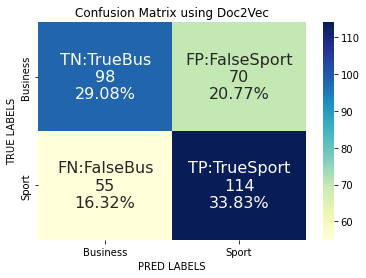

In [ ]:
# Ref confusion matrix: https://medium.com/@dtuk81/confusion-matrix-visualization-fc31e3f30fea
ax = plt.subplot()
sns.heatmap(cm_lr_doc2vec, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_lr_doc2vec, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax)
ax.set_title('Confusion Matrix using Doc2Vec')
ax.set_xlabel('PRED LABELS');ax.set_ylabel('TRUE LABELS')

In [ ]:
# Função para calcular métricas
def calc_metrics(tp, tn, fp, fn):
  accuracy = (tp + tn)/(tp + fp + tn + fn)
  precision = (tp)/(tp + fp)
  recall = (tp) / (tp + fn)
  f1_score = 2 * (precision * recall) / (precision + recall)

  return accuracy, precision, recall, f1_score

In [ ]:
tp_lr_doc2vec = 114
tn_lr_doc2vec = 98
fp_lr_doc2vec = 70
fn_lr_doc2vec = 55

acc_doc2vec_lr, prec_doc2vec_lr, recall_doc2vec_lr, f1_score_doc2vec_lr = calc_metrics(tp_lr_doc2vec, tn_lr_doc2vec, fp_lr_doc2vec, fn_lr_doc2vec)

print("/-- Métricas: Regressão Logística Doc2Vec --/")
print("Acurácia: ", round(acc_doc2vec_lr, 4))
print("Precisão: ", round(prec_doc2vec_lr, 4))# tp / (tp + fp)
print("Recall: ", round(recall_doc2vec_lr, 4))
print("F1-score: ", round(f1_score_doc2vec_lr, 4))

/-- Métricas: Regressão Logística Doc2Vec --/
Acurácia:  0.6291
Precisão:  0.6196
Recall:  0.6746
F1-score:  0.6459


### Naive-Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_doc2vec = GaussianNB().fit(X_train_doc2vec, y_train_doc2vec)

y_pred_doc2vec_nb = nb_doc2vec.predict(X_test_doc2vec)

In [ ]:
# Matriz confusão
cm_nb_doc2vec = confusion_matrix(y_test_doc2vec, y_pred_doc2vec_nb)

sport_true = int(0)
sport_pred_doc2vec_nb = int(0)
business_true = int(0)
business_pred_doc2vec_nb = int(0)

for idx, cont in enumerate(y_test_doc2vec):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_doc2vec_nb):
  if cont2 == "sport":
    sport_pred_doc2vec_nb = sport_pred_doc2vec_nb + 1
  else:
    business_pred_doc2vec_nb = business_pred_doc2vec_nb + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_doc2vec_nb)
print("Business pred ", business_pred_doc2vec_nb)
print("Confusion matrix: Logistic Regression")
print(cm_nb_doc2vec)

Sport true:  169
Business true:  168
Sport pred:  211
Business pred  126
Confusion matrix: Logistic Regression
[[ 84  84]
 [ 42 127]]


Text(17.2, 0.5, 'TRUE LABELS')

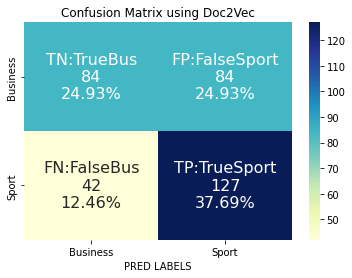

In [ ]:
group_names_nb_doc2vec = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_nb_doc2vec = ["{0:0.0f}".format(value) for value in cm_nb_doc2vec.flatten()]

group_per_nb_doc2vec = ["{0:.2%}".format(value) for value in cm_nb_doc2vec.flatten()/np.sum(cm_nb_doc2vec)]

labels_nb_doc2vec = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_lr_doc2vec, group_counts_nb_doc2vec, group_per_nb_doc2vec)]

labels_nb_doc2vec = np.asarray(labels_nb_doc2vec).reshape(2, 2)

ax_nb_doc2vec = plt.subplot()
sns.heatmap(cm_nb_doc2vec, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_nb_doc2vec, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_nb_doc2vec)
ax_nb_doc2vec.set_title('Confusion Matrix using Doc2Vec')
ax_nb_doc2vec.set_xlabel('PRED LABELS');
ax.set_ylabel('TRUE LABELS')

In [ ]:
tp_nb_doc2vec = 127
tn_nb_doc2vec = 84
fp_nb_doc2vec = 84
fn_nb_doc2vec = 42

acc_doc2vec_nb, prec_doc2vec_nb, recall_doc2vec_nb, f1_score_doc2vec_nb = calc_metrics(tp_nb_doc2vec, tn_nb_doc2vec, fp_nb_doc2vec, fn_nb_doc2vec)

print("/-- Métricas: Naive-Bayes usando Doc2Vec --/")
print("Acurácia: ", round(acc_doc2vec_nb, 4))
print("Precisão: ", round(prec_doc2vec_nb, 4))# tp / (tp + fp)
print("Recall: ", round(recall_doc2vec_nb, 4))
print("F1-score: ", round(f1_score_doc2vec_nb, 4))

/-- Métricas: Naive-Bayes usando Doc2Vec --/
Acurácia:  0.6261
Precisão:  0.6019
Recall:  0.7515
F1-score:  0.6684


### SVM

In [ ]:
from sklearn.svm import SVC

svm_doc2vec = SVC().fit(X_train_doc2vec, y_train_doc2vec)

y_pred_doc2vec_svm = svm_doc2vec.predict(X_test_doc2vec)

In [ ]:
# Matriz confusão
cm_svm_doc2vec = confusion_matrix(y_test_doc2vec, y_pred_doc2vec_svm)

sport_true = int(0)
sport_pred_doc2vec_svm = int(0)
business_true = int(0)
business_pred_doc2vec_svm = int(0)

for idx, cont in enumerate(y_test_doc2vec):
  if cont == "sport":
    sport_true = sport_true + 1
  else:
    business_true = business_true + 1

for idx2, cont2 in enumerate(y_pred_doc2vec_svm):
  if cont2 == "sport":
    sport_pred_doc2vec_svm = sport_pred_doc2vec_svm + 1
  else:
    business_pred_doc2vec_svm = business_pred_doc2vec_svm + 1

print("Sport true: ", sport_true)
print("Business true: ", business_true)
print("Sport pred: ", sport_pred_doc2vec_svm)
print("Business pred ", business_pred_doc2vec_svm)
print("Confusion matrix: Logistic Regression")
print(cm_svm_doc2vec)

Sport true:  169
Business true:  168
Sport pred:  276
Business pred  61
Confusion matrix: Logistic Regression
[[ 46 122]
 [ 15 154]]


Text(33.0, 0.5, 'TRUE LABELS')

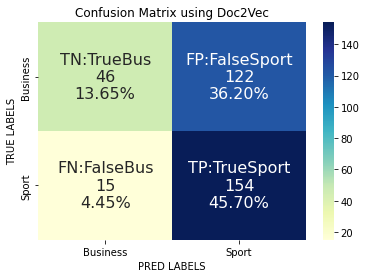

In [ ]:
group_names_svm_doc2vec = ['TN:TrueBus', 'FP:FalseSport', 'FN:FalseBus', 'TP:TrueSport']

group_counts_svm_doc2vec = ["{0:0.0f}".format(value) for value in cm_svm_doc2vec.flatten()]

group_per_svm_doc2vec = ["{0:.2%}".format(value) for value in cm_svm_doc2vec.flatten()/np.sum(cm_svm_doc2vec)]

labels_svm_doc2vec = [f"{v1}\n{v2}\n{v3}" for v1, v2, v3 in zip(group_names_svm_doc2vec, group_counts_svm_doc2vec, group_per_svm_doc2vec)]

labels_svm_doc2vec = np.asarray(labels_svm_doc2vec).reshape(2, 2)

ax_svm_doc2vec = plt.subplot()
sns.heatmap(cm_svm_doc2vec, xticklabels=['Business','Sport'], \
            yticklabels=['Business', 'Sport'],\
            annot=labels_svm_doc2vec, fmt='', annot_kws={'fontsize':16}, cmap="YlGnBu", ax=ax_svm_doc2vec)
ax_svm_doc2vec.set_title('Confusion Matrix using Doc2Vec')
ax_svm_doc2vec.set_xlabel('PRED LABELS');
ax_svm_doc2vec.set_ylabel('TRUE LABELS')

In [ ]:
tp_svm_doc2vec = 154
tn_svm_doc2vec = 46
fp_svm_doc2vec = 122
fn_svm_doc2vec = 15

acc_doc2vec_svm, prec_doc2vec_svm, recall_doc2vec_svm, f1_score_doc2vec_svm = calc_metrics(tp_svm_doc2vec, tn_svm_doc2vec, fp_svm_doc2vec, fn_svm_doc2vec)

print("/-- Métricas: Suport Vector Machine usando Count Vectorizer --/")
print("Acurácia: ", round(acc_doc2vec_svm, 4))
print("Precisão: ", round(prec_doc2vec_svm, 4))# tp / (tp + fp)
print("Recall: ", round(recall_doc2vec_svm, 4))
print("F1-score: ", round(f1_score_doc2vec_svm, 4))

/-- Métricas: Suport Vector Machine usando Count Vectorizer --/
Acurácia:  0.5935
Precisão:  0.558
Recall:  0.9112
F1-score:  0.6921


## (b) Refazer a 2a questão da 2a lista usando pelo menos 2 arquiteturas de redes neurais que usem camadas Embedding, Convolucionais e LSTM.

In [ ]:
# Arquiteturas possíveis
# 1 - Redes feedforward de uma única camada --> escolha 1
# 2 - Redes feedforward de múltiplas camadas
# 3 - Redes recorrentes --> escolha 2
# 1) Feedfoward: Embedding + convolution + LSTM - type1
# 2) Recorrentes: Embedding + convolution + Bi-LSTM - type2

from keras.preprocessing.text import Tokenizer
from keras.utils import pad_sequences
from keras.utils import to_categorical

In [ ]:
max_len_text = int(8000)
max_features = int(100)

#y = to_categorical(df_corpus['label'].values)
tokenizer_type1 = Tokenizer(num_words=max_features)
list_x_type1 = tokenizer_type1.fit_on_texts(list(df_bin_doc2vec['content']))
X = tokenizer_type1.texts_to_sequences(df_bin_doc2vec['content'])
X = pad_sequences(X, maxlen = max_len_text)

In [ ]:
y_nn = df_bin_doc2vec['label']
y_df_nn = y_nn.to_frame()
y_df_nn.head()

,label
0,business
1,business
2,business
3,business
4,business


In [ ]:
y_df_nn = y_df_nn.replace(to_replace= 'business', value=0) ## Business = 0
y_df_nn = y_df_nn.replace(to_replace= 'sport', value=1) ## Sports = 1

In [ ]:
#y_df_nn

In [ ]:
X_train_nn, X_test_nn, y_train_nn, y_test_nn = tts(X, y_df_nn, test_size=0.3, random_state=42)

In [ ]:
# Construindo a rede type1
from keras.layers import Dense, Embedding, LSTM, Conv1D
from keras.models import Sequential

model_type1 = Sequential()

# Entrada Embdedding com size=100
model_type1.add(Embedding(max_features, 100, mask_zero=True))
model_type1.add(Conv1D(2, 5, activation='relu'))
#model_type1.add(LSTM(2, return_sequences=False))
model_type1.add(LSTM(2, dropout=0.4, recurrent_dropout=0.4, return_sequences=False))

# Camda de saída
model_type1.add(Dense(1, activation='sigmoid'))

model_type1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, None, 100)         10000     
                                                                 
 conv1d (Conv1D)             (None, None, 2)           1002      
                                                                 
 lstm (LSTM)                 (None, 2)                 40        
                                                                 
 dense (Dense)               (None, 1)                 3         
                                                                 
Total params: 11,045
Trainable params: 11,045
Non-trainable params: 0
_________________________________________________________________


In [ ]:
!pip install tensorflow_addons

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     |████████████████████████████████| 1.1 MB 4.6 MB/s 


In [ ]:
import tensorflow as tf
import tensorflow_addons as tfa

In [ ]:
#lst_metrics = ['accuracy', keras.metrics.Precision, keras.metrics.Recall]
lst_metrics = ['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]

In [ ]:
# Treinando a rede
epoch_type1 = 10
batch_size_type1 = 16

model_type1.compile(loss='binary_crossentropy', optimizer='adam', metrics=lst_metrics)

str_time_type1 = time.time() # Time start

model_type1.fit(X_train_nn, y_train_nn, epochs = epoch_type1, 
                batch_size = batch_size_type1, verbose=1)

seconds_type1 = (time.time() - str_time_type1) # Time end
seconds_transform(seconds_type1)

Epoch 1/10
45/45 [==============================] - 562s 12s/step - loss: 0.6865 - accuracy: 0.5056 - precision: 0.5056 - recall: 1.0000
Epoch 2/10
45/45 [==============================] - 540s 12s/step - loss: 0.6396 - accuracy: 0.5882 - precision: 0.5511 - recall: 1.0000
Epoch 3/10
45/45 [==============================] - 537s 12s/step - loss: 0.5458 - accuracy: 0.8908 - precision: 0.8410 - recall: 0.9668
Epoch 4/10
45/45 [==============================] - 537s 12s/step - loss: 0.4795 - accuracy: 0.9286 - precision: 0.9122 - recall: 0.9501
Epoch 5/10
45/45 [==============================] - 537s 12s/step - loss: 0.4357 - accuracy: 0.9384 - precision: 0.9227 - recall: 0.9584
Epoch 6/10
45/45 [==============================] - 533s 12s/step - loss: 0.4169 - accuracy: 0.9356 - precision: 0.9339 - recall: 0.9391
Epoch 7/10
45/45 [==============================] - 534s 12s/step - loss: 0.4120 - accuracy: 0.9244 - precision: 0.9115 - recall: 0.9418
Epoch 8/10
45/45 [=======================

In [ ]:
# Avaliando o modelo
loss_model1, acc_model1, precision_model1, recall_model1 = model_type1.evaluate(X_test_nn, y_test_nn, verbose=0)
print('Accuracy NN type1:', round(acc_model1, 4))
print("Precision NN type1: ", round(precision_model1, 4))
print("Recall NN type1: ", round(recall_model1, 4))

In [ ]:
# 2) Recorrentes: Embedding + convolution + Bi-LSTM - type2
from keras.layers import Activation
from keras.layers import Bidirectional

# With custom backward layer
model_type2 = Sequential()

# Entrada Embdedding com size=100
model_type2.add(Embedding(max_features, 100, mask_zero=True))
model_type2.add(Conv1D(2, 5, activation='relu'))
model_type2.add(Bidirectional(LSTM(10, return_sequences=True), input_shape=(5, 10)))
model_type2.add(Bidirectional(LSTM(10)))
model_type2.add(Dense(1))
model_type2.add(Activation('softmax'))
#

model_type2.summary()

In [ ]:
# Treinando a rede
epoch_type2 = 10
batch_size_type2 = 64

model_type2.compile(loss='binary_crossentropy', optimizer='adam', metrics=lst_metrics)

str_time_type2 = time.time() # Time start

model_type2.fit(X_train_nn, y_train_nn, epochs=epoch_type2, 
                batch_size=batch_size_type2, verbose=1)

seconds_type2 = (time.time() - str_time_type2) # Time end
seconds_transform(seconds_type2)

In [ ]:
model_type2.metrics_names

In [ ]:
# Avaliando o modelo
loss_model2, acc_model2, precision_model2, recall_model2 = model_type2.evaluate(X_test_nn, y_test_nn, verbose=0)
print('Accuracy NN type2:', round(acc_model2, 4))
print("Precision NN type2: ", round(precision_model2, 4))
print("Recall NN type2: ", round(recall_model2, 4))

# Questão 3

## (a) Treinar uma LSTM para gerar texto. A entrada é uma ou mais palavras de uma frase.

In [ ]:
from keras.utils import pad_sequences
from keras.layers import Embedding, LSTM, Dense, Dropout
from keras.preprocessing.text import Tokenizer
from keras.callbacks import EarlyStopping
from keras.models import Sequential, load_model
import keras.utils as ku 
import pandas as pd
import numpy as np
import string, os 
import warnings
warnings.filterwarnings("ignore")
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
df_business = df_corpus.loc[df_corpus['label'] == 'business'] ## Necessário porque 12 Gb de RAM não foi suficiente
df_entertainment = df_corpus.loc[df_corpus['label'] == 'entertainment']
df_politics = df_corpus.loc[df_corpus['label'] == 'politics']
df_sport = df_corpus.loc[df_corpus['label'] == 'sport']
df_tech = df_corpus.loc[df_corpus['label'] == 'tech']

In [ ]:
n_samples = 75
frames = [df_business.sample(n = n_samples, random_state=42), df_entertainment.sample(n = n_samples, random_state=42), 
          df_politics.sample(n = n_samples, random_state=42), df_sport.sample(n = n_samples, random_state=42), df_tech.sample(n = n_samples, random_state=42)]

df_subset = pd.concat(frames)

df_subset.groupby(by=['label']).count() 

,Unnamed: 0,id,content
label,,,
business,75,75,75
entertainment,75,75,75
politics,75,75,75
sport,75,75,75
tech,75,75,75


In [ ]:
all_articles = list(df_subset.content.values)
print(len(all_articles))
print("\n")
corpus_subset = [x for x in all_articles]
corpus_subset[:1]

375




['christmas sales worst since \n\nuk retail sales fell in december  failing to meet expectations and making it by some counts the worst christmas since  \n\nretail sales dropped by   on the month in december  after a    rise in november  the office for national statistics  ons  said  the ons revised the annual  rate of growth down from the    estimated in november to     a number of retailers have already reported poor figures for december  clothing retailers and non specialist stores were the worst hit with only internet retailers showing any significant growth  according to the ons \n\nthe last time retailers endured a tougher christmas was  years previously  when sales plunged    \n\nthe ons echoed an earlier caution from bank of england governor mervyn king not to read too much into the poor december figures  some analysts put a positive gloss on the figures  pointing out that the non seasonally adjusted figures showed a performance comparable with   the november december jump last

In [ ]:
t = Tokenizer(num_words=None, filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n', lower=True, split=' ', char_level=False, oov_token=None, document_count=0)
t.fit_on_texts(corpus_subset)
print("Words counts: ", t.word_counts)
print("Words docs: ",t.word_docs)
print("Document count: ", t.document_count)
print("Word index: ", t.word_index)
print('Found %s unique tokens.' % len(t.word_index))

Words counts:  OrderedDict([('christmas', 25), ('sales', 107), ('worst', 9), ('since', 107), ('uk', 176), ('retail', 20), ('fell', 24), ('in', 2996), ('december', 61), ('failing', 9), ('to', 4329), ('meet', 19), ('expectations', 12), ('and', 3268), ('making', 54), ('it', 1287), ('by', 798), ('some', 218), ('counts', 2), ('the', 9065), ('dropped', 12), ('on', 1337), ('month', 78), ('after', 255), ('a', 3081), ('rise', 50), ('november', 31), ('office', 62), ('for', 1583), ('national', 70), ('statistics', 13), ('ons', 10), ('said', 1212), ('revised', 3), ('annual', 32), ('rate', 45), ('of', 3600), ('growth', 73), ('down', 115), ('from', 607), ('estimated', 12), ('number', 133), ('retailers', 10), ('have', 801), ('already', 86), ('reported', 35), ('poor', 19), ('figures', 73), ('clothing', 3), ('non', 27), ('specialist', 4), ('stores', 11), ('were', 402), ('hit', 61), ('with', 956), ('only', 166), ('internet', 61), ('showing', 15), ('any', 134), ('significant', 18), ('according', 72), ('la

In [ ]:
def get_sequence_of_tokens(any_corpus):
    t.fit_on_texts(any_corpus)
    total_words = len(t.word_index) + 1
    
    input_sequences = []
    for line in any_corpus:
        token_list = t.texts_to_sequences([line])[0]
        for i in range(1, len(token_list)):
            n_gram_sequence = token_list[i-1:i+3]
            input_sequences.append(n_gram_sequence)
            
    return input_sequences, total_words

In [ ]:
input_sequences, total_words = get_sequence_of_tokens(corpus_subset)

input_sequences[:10]

[[780, 138, 1995, 139],
 [138, 1995, 139, 81],
 [1995, 139, 81, 975],
 [139, 81, 975, 138],
 [81, 975, 138, 813],
 [975, 138, 813, 6],
 [138, 813, 6, 272],
 [813, 6, 272, 1996],
 [6, 272, 1996, 2],
 [272, 1996, 2, 1026]]

In [ ]:
# pad sequences 
def generate_padded_sequences(input_sequences):
    max_sequence_len = max([len(x) for x in input_sequences])
    input_sequences = np.array(pad_sequences(input_sequences, maxlen = max_sequence_len, padding = 'pre'))
    predictors, label = input_sequences[:,:-1],input_sequences[:,-1]
    label = ku.to_categorical(label, num_classes = total_words)
    
    return predictors, label, max_sequence_len

In [ ]:
predictors, label, max_sequence_len = generate_padded_sequences(input_sequences[:int(len(input_sequences)/2)])

In [ ]:
# Create model
def create_model(max_sequence_len, total_words):
    model = Sequential()
    
    # Add Input Embedding Layer
    model.add(Embedding(total_words, 10, input_length=max_sequence_len - 1))
    
    # Add Hidden Layer 1 - LSTM Layer
    model.add(LSTM(100))
    model.add(Dropout(0.1))
    
    # Add Output Layer
    model.add(Dense(total_words, activation='softmax'))

    model.compile(loss='categorical_crossentropy', optimizer='adam')
    
    return model

In [ ]:
# Tempo de execução
def seconds_transform(seconds_time):
  hours = int(seconds_time/3600)
  rest_1 = seconds_time%3600
  minutes = int(rest_1/60)
  seconds = rest_1 - 60*minutes
  print("Time: ", (hours), "h ", (minutes), "min ", round(seconds,2), " s")

In [ ]:
import time

str_time_gen_txt = time.time()

model_gen_txt = create_model(max_sequence_len, total_words)

model_gen_txt.summary()

model_gen_txt.fit(predictors, label, epochs=10)

seconds_gen_txt = (time.time() - str_time_gen_txt) # Time end
seconds_transform(seconds_gen_txt)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 3, 10)             127290    
                                                                 
 lstm (LSTM)                 (None, 100)               44400     
                                                                 
 dropout (Dropout)           (None, 100)               0         
                                                                 
 dense (Dense)               (None, 12729)             1285629   
                                                                 
Total params: 1,457,319
Trainable params: 1,457,319
Non-trainable params: 0
_________________________________________________________________
Epoch 1/10
2294/2294 [==============================] - 109s 46ms/step - loss: 7.2691
Epoch 2/10
2294/2294 [==============================] - 88s 38ms/step - loss: 6.8780
Epoch 3

In [ ]:
#model_gen_txt.save('/content/drive/MyDrive/model-pln-2022.2-list3/nn_gen_txt.h5')

In [ ]:
model_gen_txt = load_model('/content/drive/MyDrive/model-pln-2022.2-list3/nn_gen_txt.h5')

In [ ]:
print(type(model_gen_txt))

<class 'keras.engine.sequential.Sequential'>


In [ ]:
# Função para gerar texto
def generate_text(seed_text, next_words, model, max_seq_len):
  for _ in range(next_words):
    token_list = t.texts_to_sequences([seed_text])[0]
    token_list = pad_sequences([token_list], maxlen=max_seq_len-1, padding='pre')
    
    #predicted = model.predict_classes(token_list, verbose=0)    
    predicted = np.argmax(model.predict(token_list), axis=-1)

    #print("Predicted: ", predicted.shape)        
    output_word = ''
    
    for word,index in t.word_index.items():
      if index == predicted:
        output_word = word
        break
            
    seed_text = seed_text + " " + output_word
        
  return seed_text.title()

## (b) Exibir pelo menos 5 exemplos de textos dados de entrada e do texto gerado em seguida pela rede treinada. Para cada exemplo, gerar ao menos 10 palavras consecutivamente.

In [ ]:
print("/--- WORD 1 ---/")
print(generate_text("apple", 10, model_gen_txt, max_sequence_len))
print("\n/--- WORD 2 ---/")
print(generate_text("microsoft", 10, model_gen_txt, max_sequence_len))
print("\n/--- WORD 3 ---/")
print(generate_text("nintendo", 10, model_gen_txt, max_sequence_len))
print("\n/--- WORD 4 ---/")
print(generate_text("metroid", 10, model_gen_txt, max_sequence_len))
print("\n/--- WORD 5 ---/")
print(generate_text("ensure", 10, model_gen_txt, max_sequence_len))

/--- WORD 1 ---/
1/1 [==============================] - 0s 24ms/step
Apple The Film Of The World S Biggest Market In The

/--- WORD 2 ---/
1/1 [==============================] - 0s 27ms/step
Microsoft And The Aviator And The Chemical Brothers Said The Government

/--- WORD 3 ---/
1/1 [==============================] - 0s 26ms/step
Nintendo And The Tories Of The Us And The Louvre S

/--- WORD 4 ---/
1/1 [==============================] - 0s 21ms/step
Metroid And The Aviator And The Chemical Brothers Said The Government

/--- WORD 5 ---/
1/1 [==============================] - 0s 23ms/step
Ensure The Government Is Not To Be Able To Take The


# Questão 4

## (a) Extrair as etiquetas gramaticais (POS) de cada token dos textos.

In [ ]:
df_corpus.columns

Index(['Unnamed: 0', 'id', 'content', 'label'], dtype='object')

In [ ]:
df_select = df_corpus[["id", "content", "label"]]
df_select.head()

,id,content,label
0,1,ad sales boost time warner profit\n\nquarterly...,business
1,2,dollar gains on greenspan speech\n\nthe dollar...,business
2,3,yukos unit buyer faces loan claim\n\nthe owner...,business
3,4,high fuel prices hit ba s profits\n\nbritish a...,business
4,5,pernod takeover talk lifts domecq\n\nshares in...,business


In [ ]:
df_select['content'] = df_select['content'].replace(to_replace='\w*\d\w*', value='', regex=True)
df_select.head()

,id,content,label
0,1,ad sales boost time warner profit\n\nquarterly...,business
1,2,dollar gains on greenspan speech\n\nthe dollar...,business
2,3,yukos unit buyer faces loan claim\n\nthe owner...,business
3,4,high fuel prices hit ba s profits\n\nbritish a...,business
4,5,pernod takeover talk lifts domecq\n\nshares in...,business


In [ ]:
nlp = spacy.load("en_core_web_sm")

In [ ]:
tokens_lemmas_pos = []
for i in range(df_select['content'].shape[0]):
  doc = nlp(df_select['content'][i])
  for token in doc:
    tokens_lemmas_pos.append([i, token.text, token.lemma_, token.pos_, token.tag_])

df_tokens_lemmas_pos = pd.DataFrame(tokens_lemmas_pos, columns=['Text_index', 'Token', 'Lemma' ,'POS', 'Tag'])

In [ ]:
df_tokens_lemmas_pos.head()

,Text_index,Token,Lemma,POS,Tag
0,0,ad,ad,NOUN,NN
1,0,sales,sale,NOUN,NNS
2,0,boost,boost,VERB,VBP
3,0,time,time,NOUN,NN
4,0,warner,warner,PROPN,NNP


In [ ]:
df_tokens_lemmas_pos.to_csv('/content/drive/MyDrive/dataset_pln_2022.2/df_pos_corpus_bbc.csv')

## (b) Calcular e plotar um gráfico com as frequências de cada tipo gramatical.

In [ ]:
df_tokens_lemmas_pos.groupby('POS')['Token'].count()

POS
ADJ       67090
ADP      100882
ADV       30216
AUX       53564
CCONJ     25073
DET       81424
INTJ        256
NOUN     206145
NUM        7436
PART      28169
PRON      54487
PROPN     70608
PUNCT         4
SCONJ     16623
SPACE    104316
SYM           8
VERB     114907
X           379
Name: Token, dtype: int64

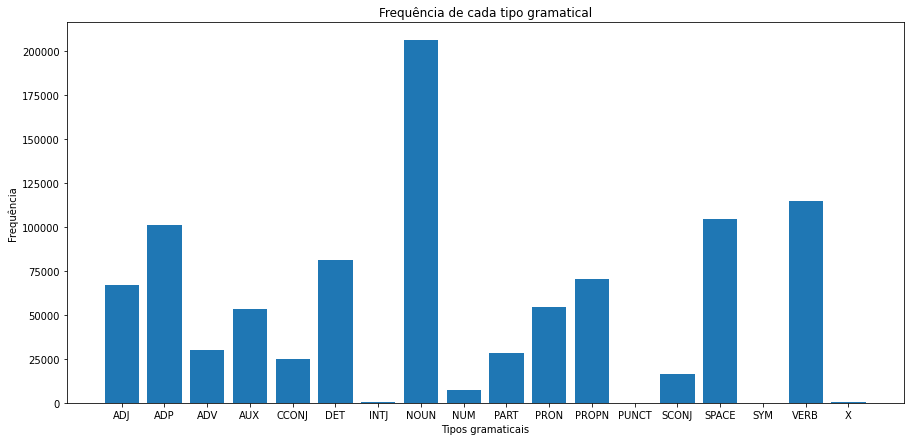

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import rcParams
rcParams['figure.figsize'] = 15, 7
frequency_pos =  df_tokens_lemmas_pos.groupby('POS')['Token'].count()

labels = frequency_pos.index
x_height = frequency_pos.values

plt.bar(labels, x_height)
plt.xlabel('Tipos gramaticais')
plt.ylabel('Frequência')
plt.title('Frequência de cada tipo gramatical')
plt.show()

## (c) Extrair entidades do tipo pessoa e lugar dos textos.

In [ ]:
texts_labels = []
for i in range(df_select['content'].shape[0]):
  doc = nlp(df_select['content'][i])
  for ent in doc.ents:
    texts_labels.append([i, ent.text, ent.label_])

df_texts_labels = pd.DataFrame(texts_labels, columns=['Text_index', 'Text', 'Label'])

In [ ]:
df_texts_labels.head()

,Text_index,Text,Label
0,0,warner,ORG
1,0,quarterly,DATE
2,0,â£,PRODUCT
3,0,the three months to december,DATE
4,0,fourth quarter,DATE


In [ ]:
# Tipo pessoa
df_person = df_texts_labels[df_texts_labels['Label'] == 'PERSON']
df_person

,Text_index,Text,Label
11,0,aol s,PERSON
12,0,aol s,PERSON
22,0,bertelsmann s,PERSON
23,0,aol europe,PERSON
25,1,greenspan speech\n\n,PERSON
...,...,...,...
49064,2223,yoran,PERSON
49069,2224,anderson,PERSON
49072,2224,charles macintyre,PERSON
49078,2224,don,PERSON


In [ ]:
# Tipo local
df_places = df_texts_labels[df_texts_labels['Label'] == 'GPE']
df_places

,Text_index,Text,Label
28,1,us,GPE
31,1,new york,GPE
37,1,london,GPE
40,1,new york,GPE
42,1,china,GPE
...,...,...,...
49039,2222,us,GPE
49070,2224,texas,GPE
49073,2224,england,GPE
49123,2224,korea,GPE


## (d) Identificar e listar as pessoas mais frequentes nos textos (considerar cada entidade 1 vez por documento).

In [ ]:
text_index_unique = df_person.groupby('Text_index')['Text'].unique()
names = []
names_counts =  dict()

for i in text_index_unique.index:
  for name in text_index_unique[i]:
    if not name in set(names):
      names.append(name)
      names_counts[name] = 1
    else:
      names_counts[name] += 1

In [ ]:
sort_orders = sorted(names_counts.items(), key=lambda x: x[1], reverse=True)
qtde = 9

aux_count = 0
for i in sort_orders:
	#print(f'{aux_count+1}° ', i[0].capitalize(), i[1])
  print('{ord}° {name} {count}'.format(ord = aux_count+1, name = i[0].capitalize(), count = i[1], ))
  if aux_count == qtde:
    break
  else:
    aux_count += 1

1° Blair 110
2° Don 89
3° Michael howard 85
4° Gordon brown 84
5° Tony blair 66
6° Brown 56
7° Charles kennedy 48
8° Howard 46
9° Williams 41
10° Mike 39
